# Advection–diffusion, Peclet number and Fourier modes

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §3.3, pp. 18–21.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

Adding constant drift v gives $c_t+vc_x=Dc_{xx}$. With length L and advection time L/v (v>0), the diffusion coefficient becomes $1/Pe$, where $Pe=vL/D$. Large Pe means advection dominates at that scale; it does not mean diffusion vanishes at every scale.

For a periodic Fourier mode $e^{ikx}$, substitution gives $\hat c_k'=(-Dk^2-ivk)\hat c_k$. Diffusion damps amplitude by $e^{-Dk^2t}$ and advection rotates phase by $e^{-ivkt}$. Higher wavenumbers decay faster. A sum of modes solves the linear equation by superposition.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

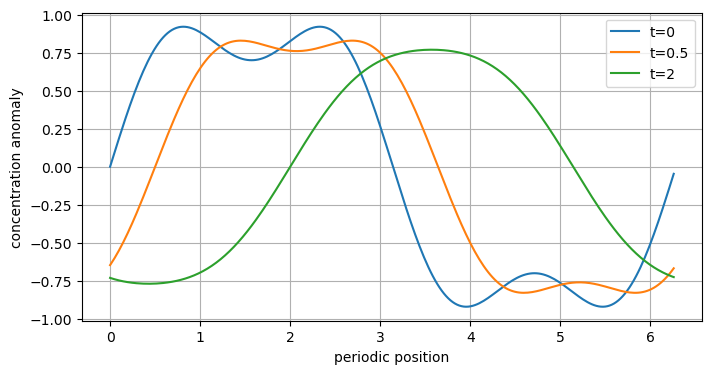

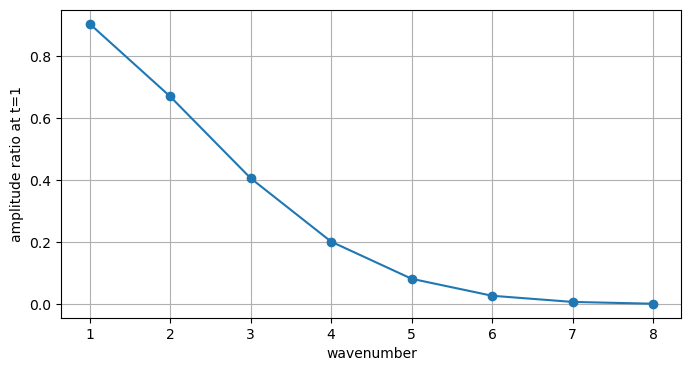

In [2]:
x=np.linspace(0,2*np.pi,256,endpoint=False);v=1.;D=.1
for t in [0,.5,2]:
 c=np.exp(-D*t)*np.sin(x-v*t)+.3*np.exp(-9*D*t)*np.sin(3*(x-v*t))
 plt.plot(x,c,label=f"t={t}")
plt.xlabel("periodic position");plt.ylabel("concentration anomaly");plt.legend();plt.show()
k=np.arange(1,9);plt.plot(k,np.exp(-D*k*k),"o-");plt.xlabel("wavenumber");plt.ylabel("amplitude ratio at t=1");plt.show()
assert np.all(np.diff(np.exp(-D*k*k))<0)

## Read the result

The fine-scale component disappears first. A Fourier solution gives a reference for numerical PDE solvers, separating phase error from damping error.

## Your turn

Double v while holding D fixed. Predict which part of the modal solution changes, then verify.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.